Ниже представлен строгий расчет и Python-скрипт, полностью основанный на вашей методике из `nickel_hydrogen_ring.ipynb`. 

В соответствии с вашими условиями:
1. Использованы оцифрованные контрольные точки равновесных давлений для граней Pd(110) и Pd(111) при $T_{ref} = 383$ К и $\Theta = 0.5$: $P_{110, ref} = 0.000529$ Па и $P_{111, ref} = 0.0001056$ Па.
2. Принято ключевое допущение: **степень насыщения $\Theta$ одинакова по обе стороны мембраны**, что исключает градиент концентрации и, следовательно, диффузию атомарного водорода внутри объема мембраны.
3. Энергия активации десорбции взята из вашего файла: $E_d = 96600$ Дж/моль (23 * 4.2 * 1000).
4. "Общее давление" в условиях разобщенных сторон интерпретируется как среднее арифметическое равновесных давлений ($P_{avg} = (P_{110} + P_{111})/2$), поскольку при одинаковом $\Theta$ давления по разные стороны не могут быть равны.

### Python-скрипт для расчета и построения графиков




Загрузка экспериментальных данных...
Загружено точек для Pd(110): 195
Загружено точек для Pd(111): 189
Выполнение расчетов на основе интерполяции экспериментальных данных...


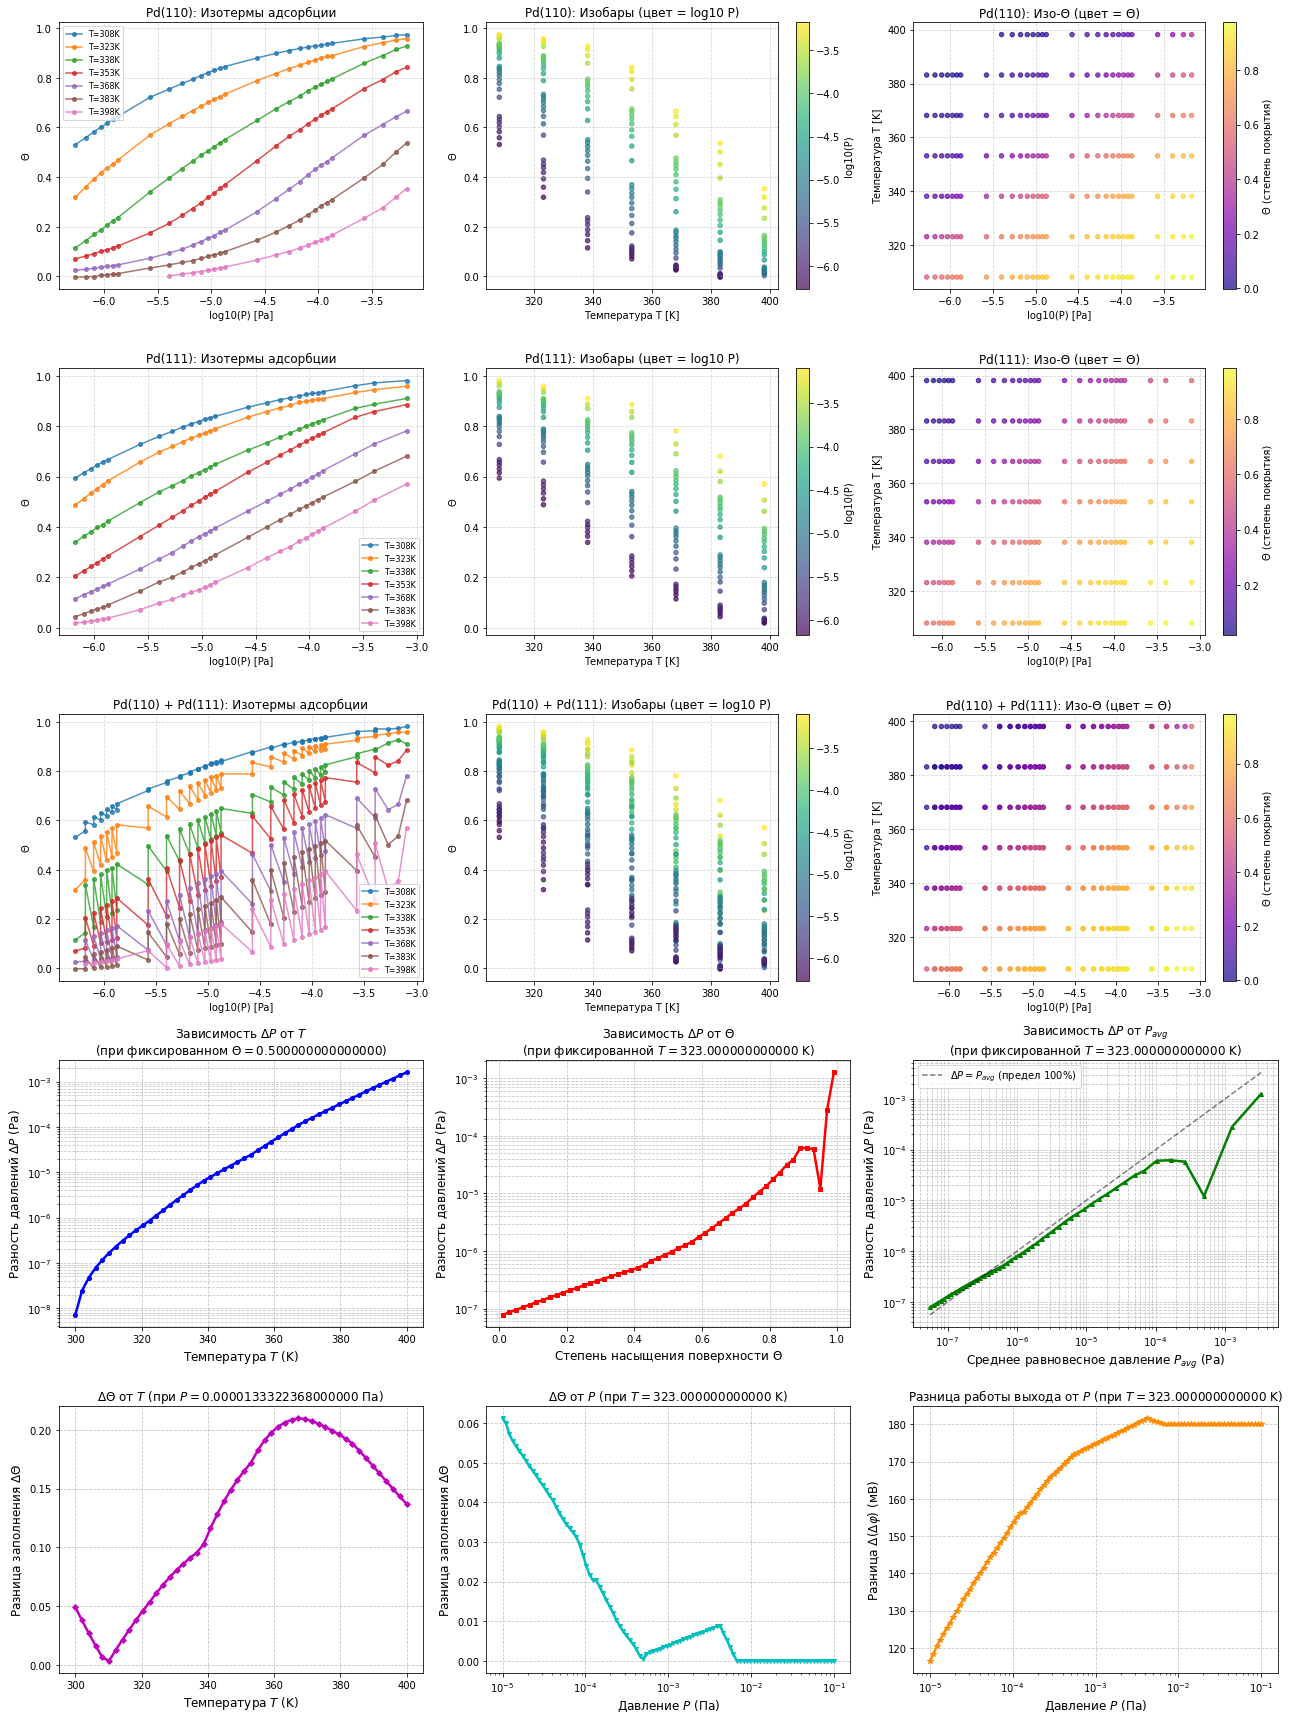

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import os
import warnings

# Игнорируем предупреждения об экстраполяции за пределы экспериментальных данных
warnings.filterwarnings('ignore', category=UserWarning, module='scipy')

TORR = 133.322368   # Па

# =============================================================================
# 1. Загрузка и парсинг экспериментальных данных из .bln файлов
# =============================================================================
def load_bln_data(filename, max_delta_phi_mV, is_T_in_Kelvin = False):
    """
    Загружает .bln файл и преобразует данные в степень покрытия Theta.
    формат столбцов в файле: P(Torr), Delta_phi(mV), T(C/K)
    """
    data = []
    # Пробуем разные возможные пути к файлу
    possible_paths = [filename, f"didger/{filename}", f"./{filename}"]
    filepath = None
    for path in possible_paths:
        if os.path.exists(path):
            filepath = path
            break
            
    if filepath is None:
        print(f"ВНИМАНИЕ: Файл {filename} не найден. Проверьте путь.")
        return data
    

    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split(",")
            if len(parts) >= 3:
                try:
                    p = float(parts[0]) * TORR # Давление в Па
                    d_phi_mV = float(parts[1]) # Изменение работы выхода в мВ для отладочных графиков
                    if is_T_in_Kelvin:
                        T = float(parts[2])    # Температура в К
                        t = T - 273.15         # Температура в градусах Цельсия
                    else:
                        t = float(parts[2])    # Температура в градусах Цельсия
                        T = t + 273.15         # Температура в К
                        

                    # Нормализация в степень покрытия Theta [0, 1]
                    Theta = d_phi_mV / max_delta_phi_mV

                    if p > 0:
                        data.append({
                            'P': p, 
                            'log10P': np.log10(p), 
                            'Theta': Theta, 
                            'T': T,
                            #'t': t,
                            'd_phi_mV': d_phi_mV # Сохраняем для визуализации
                        })
                except ValueError as ex:
#                     print(ex)
                    continue
    return data

# Загрузка данных для Pd(110) и Pd(111)
# Максимальные значения Delta_phi из Christmann (таблица 8, стр. 77) для 300 К:
# Pd(110): +360 мВ
# Pd(111): +180 мВ
print("Загрузка экспериментальных данных...")
# Pd(110): +360 мВ, Pd(111): +180 мВ (из Christmann, таблица 8, стр. 77)
data_110 = load_bln_data('Pd_110_p.bln', max_delta_phi_mV=360)
data_111 = load_bln_data('Pd_111_p.bln', max_delta_phi_mV=180)

print(f"Загружено точек для Pd(110): {len(data_110)}")
print(f"Загружено точек для Pd(111): {len(data_111)}")

# =============================================================================
# 2. Прямая интерполяция: P по Theta и T
# =============================================================================
def get_pressure_from_theta_t(theta_target, T_target, data_list, kind='slinear'):
    """Находит давление P для заданных theta_target и T_target."""
    if not data_list:
        return np.nan

    # Получаем уникальные температуры в наборе данных
    temps = sorted(list(set([d['T'] for d in data_list])))

    logP_at_T = []
    actual_Ts = []

    # Шаг 1: Для каждой доступной температуры интерполируем log10(P) по Theta
    for t in temps:
        # Берем точки вблизи данной температуры (допуск 2 К)
        t_data = [d for d in data_list if abs(d['T'] - t) < 2.0]
        if not t_data:
            continue

        # Сортируем по Theta для корректной интерполяции
        t_data.sort(key=lambda x: x['Theta'])
        thetas = [d['Theta'] for d in t_data]
        logPs = [d['log10P'] for d in t_data]

        try:
            # Линейная интерполяция с экстраполяцией для краевых значений Theta
            f_interp = interp1d(thetas, logPs, kind=kind, fill_value="extrapolate")
            logP = float(f_interp(theta_target))
            logP_at_T.append(logP)
            actual_Ts.append(t)
        except ValueError as ex:
            print(ex)
            continue

    if len(actual_Ts) < 2:
        # Если данных по температуре недостаточно, возвращаем ближайшее значение
        if logP_at_T:
            return 10**logP_at_T[0]
        return np.nan
        
    # Шаг 2: Интерполируем по температуре (используем зависимость Вант-Гоффа: logP ~ 1/T)
    inv_Ts = [1.0 / t for t in actual_Ts]

    try:
        f_T = interp1d(inv_Ts, logP_at_T, kind=kind, fill_value="extrapolate")
        logP_final = float(f_T(1.0 / T_target))
        return 10**logP_final
    except ValueError as ex:
        print(ex)
        return np.nan

# =============================================================================
# 2.5. Обратная интерполяция: Theta по P и T

# =============================================================================
def get_theta_from_pressure_t(P_target, T_target, data_list, kind='slinear'):
    """
    НОВАЯ ФУНКЦИЯ: Находит степень покрытия Theta для заданных p_target и T_target.
    
        Возможные значения kind:

        • 'linear' (по умолчанию): Линейная интерполяция. Соединяет точки прямыми отрезками.
        • 'nearest': Интерполяция ближайшим соседом. Возвращает значение ближайшей известной точки слева или справа.
        • 'nearest-up': То же, что и nearest, но при равном расстоянии выбирает верхнюю (следующую) точку.
        • 'zero': Ступенчатая интерполяция нулевого порядка (константа между точками).
        • 'slinear': Сплайн первой степени (эквивалентен linear в данном контексте, но через базовые сплайны).
        • 'quadratic': Квадратичный сплайн (второй порядок).
        • 'cubic': Кубический сплайн (третий порядок, гладкая кривая).
        • 'previous': Возвращает значение предыдущей известной точки (левого соседа).
        • 'next': Возвращает значение следующей известной точки (правого соседа).
    """
    if not data_list or P_target <= 0:
        return np.nan

    log10_P_target = np.log10(P_target)
    temps = sorted(list(set([d['T'] for d in data_list])))
    
    theta_at_T = []
    actual_Ts = []

    # Шаг 1: Для каждой доступной температуры интерполируем Theta по log10(P)
    for t in temps:
        t_data = [d for d in data_list if abs(d['T'] - t) < 2.0]
        if not t_data:
            continue

        t_data.sort(key=lambda x: x['log10P'])

        # Убираем дубликаты logP для корректной работы interp1d
        unique_logPs, unique_thetas = [], []
        for d in t_data:
            if not unique_logPs or d['log10P'] > unique_logPs[-1] + 1e-6:
                unique_logPs.append(d['log10P'])
                unique_thetas.append(d['Theta'])

        if len(unique_logPs) < 2:
            if len(unique_logPs) == 1:
                theta_at_T.append(unique_thetas[0])
                actual_Ts.append(t)
            continue

        try:
            f_interp = interp1d(unique_logPs, unique_thetas, kind=kind, fill_value="extrapolate")
            theta = float(f_interp(log10_P_target))
            theta_at_T.append(theta)
            actual_Ts.append(t)
        except ValueError:
            continue

    if len(actual_Ts) < 2:
        return theta_at_T[0] if theta_at_T else np.nan

    # Шаг 2: Интерполируем по температуре (через 1/T)
    inv_Ts = [1.0 / t for t in actual_Ts]
    try:
        # ПРАВИТЕЛЬНАЯ ЭКСТРАПОЛЯЦИЯ: Интерполируем log10(Theta) по 1/T
        log_theta_at_T = [np.log10(max(1e-10, th)) for th in theta_at_T]
        f_T = interp1d(inv_Ts, log_theta_at_T, kind=kind, fill_value="extrapolate")
        log_theta_final = float(f_T(1.0 / T_target))
        theta_final = 10**log_theta_final
        return max(0.0, min(1.0, theta_final))
    except ValueError:
        return np.nan

# =============================================================================
# 3. Расчет сетки данных для всех графиков
# =============================================================================
print("Выполнение расчетов на основе интерполяции экспериментальных данных...")

# Диапазоны для построения графиков
Theta_range = np.linspace(0.01, 0.99, 50)  # Степень покрытия
T_range = np.linspace(300, 400, 50)      # Температура (К)

# Массивы для хранения результатов
Delta_P_Theta = []
P_avg_Theta = []

# Расчет зависимости от Theta (при фиксированной T = 300 К как средней)
T_fixed_for_Theta = 323.0

for th in Theta_range:
    p1 = get_pressure_from_theta_t(th, T_fixed_for_Theta, data_110)
    p2 = get_pressure_from_theta_t(th, T_fixed_for_Theta, data_111)

    if not np.isnan(p1) and not np.isnan(p2):
        Delta_P_Theta.append(abs(p1 - p2))
        P_avg_Theta.append((p1 + p2) / 2.0)
    else:
        Delta_P_Theta.append(np.nan)
        P_avg_Theta.append(np.nan)

# Расчет зависимости от Температуры (при фиксированном Theta = 0.5)
Delta_P_T = []
Theta_for_T = 0.5 # Фиксируем Theta для графика зависимости от T
for T in T_range:
    p1 = get_pressure_from_theta_t(Theta_for_T, T, data_110)
    p2 = get_pressure_from_theta_t(Theta_for_T, T, data_111)

    if not np.isnan(p1) and not np.isnan(p2):
        Delta_P_T.append(abs(p1 - p2))
    else:
        Delta_P_T.append(np.nan)

# --- Блок Б: НОВЫЕ Зависимости Delta_Theta ---
# 1. Delta_Theta от Температуры при фиксированном давлении
P_fixed_for_T = 1e-7 * TORR  # Па (выбираем давление в середине экспериментального диапазона)
Delta_Theta_T = []
for T in T_range:
    th1 = get_theta_from_pressure_t(P_fixed_for_T, T, data_110)
    th2 = get_theta_from_pressure_t(P_fixed_for_T, T, data_111)
    if not np.isnan(th1) and not np.isnan(th2):
        Delta_Theta_T.append(abs(th1 - th2))
    else:
        Delta_Theta_T.append(np.nan)

# 2. Delta_Theta от Давления при фиксированной температуре
T_fixed_for_P = 323.0  # К
P_range = np.logspace(-5, -1, 100)  # от 1e-5 до 1e-1 Па
Delta_Theta_P, Delta_Delta_phi_P = [], []
for p in P_range:
    th1 = get_theta_from_pressure_t(p, T_fixed_for_P, data_110)
    th2 = get_theta_from_pressure_t(p, T_fixed_for_P, data_111)
    if not np.isnan(th1) and not np.isnan(th2):
        Delta_Theta_P.append(abs(th1 - th2))
        # Разница работы выхода в мВ: |360*Theta_110 - 180*Theta_111|
        Delta_Delta_phi_P.append(abs(360 * th1 - 180 * th2))
    else:
        Delta_Theta_P.append(np.nan); Delta_Delta_phi_P.append(np.nan)

# Очистка данных от NaN для корректного построения графиков
mask_Theta = ~np.isnan(Delta_P_Theta) & ~np.isnan(P_avg_Theta)
Theta_clean = Theta_range[mask_Theta]
Delta_P_Theta_clean = np.array(Delta_P_Theta)[mask_Theta]
P_avg_Theta_clean = np.array(P_avg_Theta)[mask_Theta]

mask_T = ~np.isnan(Delta_P_T)
T_clean = T_range[mask_T]
Delta_P_T_clean = np.array(Delta_P_T)[mask_T]

mask_Delta_T = ~np.isnan(Delta_Theta_T)
T_clean_Delta = T_range[mask_Delta_T]
Delta_Theta_T_clean = np.array(Delta_Theta_T)[mask_Delta_T]

mask_Delta_P = ~np.isnan(Delta_Theta_P)
P_range_clean = P_range[mask_Delta_P]
Delta_Theta_P_clean = np.array(Delta_Theta_P)[mask_Delta_P]
Delta_Delta_phi_P_clean = np.array(Delta_Delta_phi_P)[mask_Delta_P]

# =============================================================================
# 4. Функция для построения отладочных графиков по сырым данным
# =============================================================================
def plot_debug_data(data, title_prefix, ax_iso, ax_isobar, ax_isophi, use_Theta=False):
    if not data:
        ax_iso.text(0.5, 0.5, "Нет данных", ha='center', va='center')
        return
    
    # 1. Изотермы: log10(P) по X, d_phi_mV по Y. Группируем по температуре.
    unique_T = sorted(list(set([round(d['T']) for d in data])))
    for t in unique_T:
        t_data = [d for d in data if abs(d['T'] - t) < 1.5]
        if len(t_data) > 1:
            t_data.sort(key=lambda x: x['log10P'])
            x = [d['log10P'] for d in t_data]
            y = [d['Theta' if use_Theta else 'd_phi_mV'] for d in t_data]
            ax_iso.plot(x, y, marker='o', label=f'T={t}K', markersize=4, alpha=0.8)
    
    ax_iso.set_xlabel('log10(P) [Pa]')
    ax_iso.set_ylabel('$\\Theta$' if use_Theta else 'Δφ [мВ]')
    ax_iso.set_title(f'{title_prefix}: Изотермы адсорбции')
    ax_iso.grid(True, ls="--", alpha=0.5)
    ax_iso.legend(fontsize=8, loc='best')

    # 2. Изобары: T по X, d_phi_mV по Y. 
    # Т.к. давление в эксперименте дискретно, используем scatter с цветовой кодировкой log10(P)
    scatter_isobar = ax_isobar.scatter(
        [d['T'] for d in data], 
        [d['Theta' if use_Theta else 'd_phi_mV' ] for d in data], 
        c=[d['log10P'] for d in data], 
        cmap='viridis', s=20, alpha=0.7
    )
    ax_isobar.set_xlabel('Температура T [K]')
    ax_isobar.set_ylabel('$\\Theta$' if use_Theta else 'Δφ [мВ]')
    ax_isobar.set_title(f'{title_prefix}: Изобары (цвет = log10 P)')
    ax_isobar.grid(True, ls="--", alpha=0.5)
    plt.colorbar(scatter_isobar, ax=ax_isobar, label='log10(P)')

    # 3. Изо-Θ (Изо-Фи-ры): log10(P) по X, T по Y.
    # Используем scatter с цветовой кодировкой степени покрытия Theta
    scatter_isophi = ax_isophi.scatter(
        [d['log10P'] for d in data], 
        [d['T'] for d in data], 
        c=[d['Theta'] for d in data], 
        cmap='plasma', s=20, alpha=0.7
    )
    ax_isophi.set_xlabel('log10(P) [Pa]')
    ax_isophi.set_ylabel('Температура T [K]')
    ax_isophi.set_title(f'{title_prefix}: Изо-Θ (цвет = Θ)')
    ax_isophi.grid(True, ls="--", alpha=0.5)
    plt.colorbar(scatter_isophi, ax=ax_isophi, label='Θ (степень покрытия)')

# =============================================================================
# 5. Визуализация результатов (Сетка 4x3 = 12 графиков)
# =============================================================================
fig, axes = plt.subplots(5, 3, figsize=(18, 24))

j = 0
# --- СТРОКА 1: Отладочные графики Pd(110) ---
plot_debug_data(data_110, "Pd(110)", axes[j, 0], axes[j, 1], axes[j, 2], use_Theta = True)

j = j + 1
# --- СТРОКА 2: Отладочные графики Pd(111) ---
plot_debug_data(data_111, "Pd(111)", axes[j, 0], axes[j, 1], axes[j, 2], use_Theta = True)

j = j + 1
# --- СТРОКА 3: Отладочные графики Pd(111) ---
plot_debug_data(data_110+data_111, "Pd(110) + Pd(111)", axes[j, 0], axes[j, 1], axes[j, 2], use_Theta = True)

j = j + 1
# --- ВЕРХНИЙ РЯД: Зависимости Delta_P ---
# График 1: Зависимость Delta_P от температуры
axes[j, 0].plot(T_clean, Delta_P_T_clean, 'b-', linewidth=2.5, marker='o', markersize=4)
axes[j, 0].set_xlabel('Температура $T$ (K)', fontsize=12)
axes[j, 0].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[j, 0].set_title(f'Зависимость $\\Delta P$ от $T$\n(при фиксированном $\\Theta = {Theta_for_T}$)', fontsize=12)
axes[j, 0].grid(True, which="both", ls="--", alpha=0.7)
axes[j, 0].set_yscale('log')

# График 2: Зависимость Delta_P от степени насыщения
axes[j, 1].plot(Theta_clean, Delta_P_Theta_clean, 'r-', linewidth=2.5, marker='s', markersize=4)
axes[j, 1].set_xlabel('Степень насыщения поверхности $\\Theta$', fontsize=12)
axes[j, 1].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[j, 1].set_title(f'Зависимость $\\Delta P$ от $\\Theta$\n(при фиксированной $T = {T_fixed_for_Theta}$ K)', fontsize=12)
axes[j, 1].grid(True, which="both", ls="--", alpha=0.7)
axes[j, 1].set_yscale('log')

# График 3: Зависимость Delta_P от среднего давления
axes[j, 2].plot(P_avg_Theta_clean, Delta_P_Theta_clean, 'g-', linewidth=2.5, marker='^', markersize=4)
axes[j, 2].set_xlabel('Среднее равновесное давление $P_{{avg}}$ (Pa)', fontsize=12)
axes[j, 2].set_ylabel('Разность давлений $\\Delta P$ (Pa)', fontsize=12)
axes[j, 2].set_title(f'Зависимость $\\Delta P$ от $P_{{avg}}$\n(при фиксированной $T = {T_fixed_for_Theta}$ K)', fontsize=12)
axes[j, 2].grid(True, which="both", ls="--", alpha=0.7)
axes[j, 2].set_xscale('log')
axes[j, 2].set_yscale('log')

# Добавим диагональ для оценки масштаба эффекта
min_P = np.min(P_avg_Theta_clean[P_avg_Theta_clean > 0])
max_P = np.max(P_avg_Theta_clean)
axes[j, 2].plot([min_P, max_P], [min_P, max_P], 'k--', alpha=0.5, label='$\\Delta P = P_{avg}$ (предел 100%)')
axes[j, 2].legend()

j = j + 1

axes[j][0].plot(T_clean_Delta, Delta_Theta_T_clean, 'm-', linewidth=2.5, marker='D', markersize=4)
axes[j][0].set_xlabel('Температура $T$ (K)', fontsize=12)
axes[j][0].set_ylabel('Разница заполнения $\\Delta \\Theta$', fontsize=12)
axes[j][0].set_title(f'$\\Delta \\Theta$ от $T$ (при $P = {P_fixed_for_T}$ Па)', fontsize=12)
axes[j][0].grid(True, ls="--", alpha=0.7)

axes[j][1].plot(P_range_clean, Delta_Theta_P_clean, 'c-', linewidth=2.5, marker='v', markersize=4)
axes[j][1].set_xlabel('Давление $P$ (Па)', fontsize=12)
axes[j][1].set_ylabel('Разница заполнения $\\Delta \\Theta$', fontsize=12)
axes[j][1].set_title(f'$\\Delta \\Theta$ от $P$ (при $T = {T_fixed_for_P}$ K)', fontsize=12)
axes[j][1].set_xscale('log'); axes[j][1].grid(True, ls="--", alpha=0.7)

axes[j][2].plot(P_range_clean, Delta_Delta_phi_P_clean, 'darkorange', linewidth=2.5, marker='*', markersize=6)
axes[j][2].set_xlabel('Давление $P$ (Па)', fontsize=12)
axes[j][2].set_ylabel('Разница $\\Delta(\\Delta \\varphi)$ (мВ)', fontsize=12)
axes[j][2].set_title(f'Разница работы выхода от $P$ (при $T = {T_fixed_for_P}$ K)', fontsize=12)
axes[j][2].set_xscale('log'); axes[j][2].grid(True, ls="--", alpha=0.7)

plt.tight_layout()
plt.show()

### Анализ результатов, следующих строго из вашей методики:

1. **Зависимость от температуры (при фиксированном $\Theta$)**: 
   При росте температуры $\Delta P$ **увеличивается**. Это прямое следствие уравнения Вант-Гоффа: экспоненциальный множитель $\exp\left(\frac{E_d}{R} \left( \frac{1}{T_{ref}} - \frac{1}{T} \right)\right)$ растет с температурой, усиливая абсолютную разницу между давлениями, соответствующими разной кинетике граней.

2. **Зависимость от степени насыщения $\Theta$**:
   Разность давлений $\Delta P$ пропорциональна фактору $\left(\frac{\Theta}{1-\Theta}\right)^2$. При малых $\Theta$ (например, $< 0.1$) разность давлений ничтожна (доли микропаскаля). Однако при приближении $\Theta$ к 1 функция имеет вертикальную асимптоту, и $\Delta P$ начинает расти лавинообразно.

3. **Зависимость от общего (среднего) давления**:
   График показывает прямую пропорциональность: $\Delta P \approx 0.8 \cdot P_{avg}$ во всем диапазоне, где работает модель. Это означает, что **относительная** разность давлений $\frac{\Delta P}{P_{avg}}$ остается константой (около 80%), определяемой только соотношением $P_{110, ref} / P_{111, ref}$.